# Figure S4: QTL discovery by population

QTL discovery proportions across ancestry groups and molecular assays.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig1_gene_reference](../../preparation/Fig1/00_gene_reference.R): Extract the GENCODE v48 gene records and stable IDs from the raw GTF.
- [fig1_population_discovery](../../preparation/Fig1/06_population_discovery.R): Recompute the historical S4 BH discovery proportions within each raw permutation-result file; count the shared reference-cohort samples.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Count reference samples and test discovery in each source table

The historical panel uses BH FDR within each permutation-result file. Main Figure 1 novelty uses source qval.
The sample sizes are common RNA reference-cohort counts reused across assays.


In [2]:
assays <- c("eQTL", "sQTL", "pQTL")
groups <- c("COMB", "AFR", "AMR", "EAS", "EUR", "SAS", "MID")
samples <- read_tsv(prep_input("input", "reference/COMB_eQTL_9k_sample_list.tsv"),
  col_types = cols_only(research_id = col_character()), progress = FALSE)
ancestry <- read_tsv(prep_input("input", "echo_v4_r2.ancestry_preds.tsv"),
  col_types = cols_only(research_id = col_character(), ancestry_pred_other = col_character()), progress = FALSE) %>%
  semi_join(samples, by = "research_id")
stopifnot(nrow(samples) == 8895L, !anyDuplicated(samples$research_id),
          nrow(ancestry) == nrow(samples), !anyDuplicated(ancestry$research_id), !anyNA(ancestry))
reference_n <- ancestry %>% mutate(population = str_to_upper(ancestry_pred_other)) %>% count(population) %>%
  bind_rows(tibble(population = "COMB", n = nrow(samples)))
fills <- c(COMB = "#CF597E", AFR = "#C8D892", AMR = "#7FC385", EAS = "#ECA676",
           EUR = "#30AC86", SAS = "#EBCE8D", MID = "#E47D72")
s4 <- crossing(assay = assays, population = groups) %>% pmap_dfr(function(assay, population) {
  relative <- if (assay == "pQTL") paste0("Fig1Data/pQTL/AoU_10750_", population, "_pQTL.cis_qtl.txt.gz") else
    paste0("Fig1Data/", assay, "/", population, ".cis_qtl.txt.gz")
  message("S4: Calculate BH FDR within ", assay, " / ", population)
  d <- read_tsv(prep_input("input", relative),
    col_types = cols_only(pval_beta = col_character()), progress = FALSE)
  fdr <- p.adjust(as.double(d$pval_beta), method = "BH")
  stopifnot(!anyNA(fdr), all(between(fdr, 0, 1)))
  tibble(assay, population, proportion_significant = mean(fdr < .05), source_n_tested = nrow(d),
         significant_count_from_saved_summary = sum(fdr < .05))
}) %>% left_join(reference_n, by = "population", relationship = "many-to-one") %>%
  transmute(assay = factor(assay, levels = assays),
    population = factor(recode(population, COMB = "Combined"), levels = c("Combined", groups[-1])),
    proportion_significant, source_n_tested, significant_count_from_saved_summary,
    source_reference_sample_n = n, colour = unname(fills[as.character(recode(population, Combined = "COMB"))]),
    marker = if_else(population == "Combined", 23L, 21L)) %>% arrange(assay, population)

message("Calculated discovery proportions and counts from 21 source result tables.")


S4: Calculate BH FDR within eQTL / AFR


S4: Calculate BH FDR within eQTL / AMR


S4: Calculate BH FDR within eQTL / COMB


S4: Calculate BH FDR within eQTL / EAS


S4: Calculate BH FDR within eQTL / EUR


S4: Calculate BH FDR within eQTL / MID


... (12 outputs left out)

S4: Calculate BH FDR within sQTL / EUR


S4: Calculate BH FDR within sQTL / MID


S4: Calculate BH FDR within sQTL / SAS


Calculated discovery proportions and counts from 21 source result tables.


## Draw the calculated discovery proportions

Each point is a population and assay summary. The x axis uses the counted reference sample count. It is not an assay-specific participant count. No confidence interval or fitted curve is added.


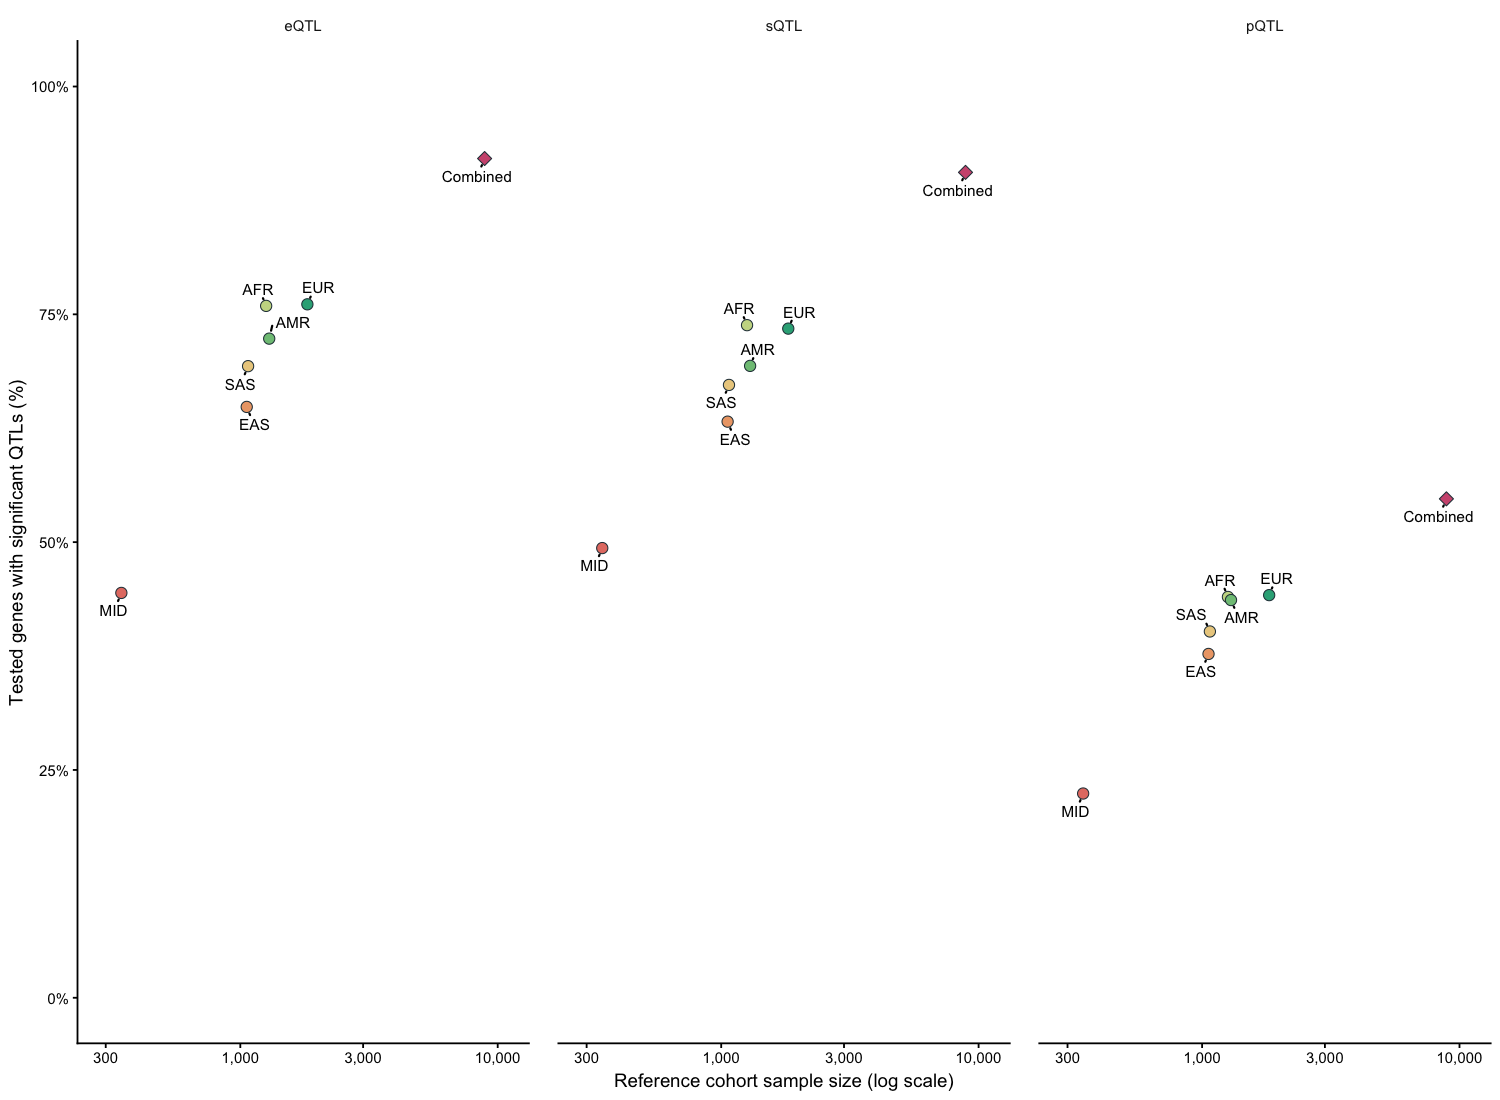

In [3]:
suppressPackageStartupMessages(library(ggrepel))
fills <- s4 %>% distinct(population, colour) %>% deframe()
shapes <- s4 %>% distinct(population, marker) %>% deframe()
figure <- ggplot(s4, aes(source_reference_sample_n, proportion_significant)) +
  geom_point(aes(fill = population, shape = population), size = 2.3, colour = "#263B45", stroke = 0.35) +
  geom_text_repel(aes(label = population), seed = 71, size = 2.6,
                  min.segment.length = 0, box.padding = 0.3,
                  point.padding = 0.2, max.overlaps = Inf) +
  facet_grid(~assay) +
  scale_fill_manual(values = fills) +
  scale_shape_manual(values = shapes) +
  scale_x_log10(limits = c(280, 11000), breaks = c(300, 1000, 3000, 10000), labels = scales::label_comma()) +
  scale_y_continuous(limits = c(0, 1), labels = scales::label_percent(), breaks = seq(0, 1, 0.25)) +
  labs(x = "Reference cohort sample size (log scale)", y = "Tested genes with significant QTLs (%)") +
  theme_classic(base_size = 9) +
  theme(strip.background = element_blank(), legend.position = "none",
        panel.spacing.x = grid::unit(5, "mm"))
print(figure)


## Save aggregate outputs

Save the figure and the 21 study summaries. No participant records are exported. The source field source_n_tested counts tested rows, not significant genes.


In [4]:
save_plot(figure, "supplements/S4", 184, 85)
readr::write_tsv(s4 %>% select(assay, population, proportion_significant, source_n_tested,
                              significant_count_from_saved_summary, source_reference_sample_n),
                 output_file("supplements/S4_summary.tsv"))


Export aggregate plot: supplements/S4
